# 02b - Preguntas e hipótesis (EDA)

## Objetivo de este cuaderno

Aquí respondemos a las preguntas 1 a 7 del EDA y hacemos una primera validación de las hipótesis H1, H2 y H3. Trabajamos con el dataset ya limpio que guardamos en 02_limpieza, así que los cortes y el tratamiento de nulos ya están aplicados. No modificamos df.

- **Lee:** data/processed/coches_limpio.csv
- **Guarda:** solo figuras en outputs/figures

### Importar librerías

Cargamos pandas, numpy, matplotlib y seaborn, que usaremos en todo el análisis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Cargar el dataset

Leemos el dataset limpio y mostramos las primeras filas para comprobar que la carga es correcta.

In [2]:
df = pd.read_csv('../data/processed/coches_limpio.csv')
df.head(10)

,make,model,price,fuel,year,kms,power,doors,shift,photos,is_professional,province,publish_date
0,CITROEN,C1,6200,Gasolina,2017,50071,82,5,Manual,6,True,Tenerife,2021-01-02
1,FORD,Transit Connect,7851,Diésel,2016,103000,100,4,Manual,10,True,Barcelona,2020-12-16
2,VOLKSWAGEN,Caravelle,19426,Diésel,2014,120000,140,4,Manual,9,True,Navarra,2020-11-25
3,FORD,Transit,22850,Diésel,2017,107000,130,2,Manual,4,True,Sevilla,2021-01-12
4,PEUGEOT,3008,11490,Gasolina,2016,78665,130,5,Manual,32,True,Madrid,2021-01-08
5,LAND-ROVER,Discovery Sport,28500,Diésel,2017,36238,150,5,Automático,47,True,Baleares,2021-01-12
6,HONDA,Civic,8200,Diésel,2012,203000,150,5,Manual,15,False,Barcelona,2020-12-03
7,CITROEN,Berlingo,12100,Gasolina,2018,45000,110,5,Manual,6,False,Alicante,2020-11-06
8,NISSAN,NOTE,6300,Gasolina,2016,77000,80,5,Manual,6,False,Barcelona,2020-12-14
9,CITROEN,Berlingo,13900,Diésel,2017,81000,100,5,Manual,21,True,Murcia,2021-01-07


## Preguntas e hipótesis

### Hipótesis previas

Estas hipótesis se escribieron **antes de explorar los datos**. Se hace así para no ajustarlas a lo que vemos: si las escribiéramos después, sería muy fácil "acertar" siempre.

- **H1:** los coches de alta gama se deprecian (pierden valor con los años) más rápido.
- **H2:** hay marcas que se deprecian menos que la media y otras que se deprecian más.
- **H3:** comparando coches de año similar, los eléctricos son más caros que los diésel, y los diésel más que los gasolina.



### Pregunta 1: ¿Cómo se distribuye el precio y qué valores raros hay?

**Por qué importa para el negocio:** el precio es lo que queremos predecir. Conocer el rango habitual nos dice para qué coches será fiable la tasación, y saber cuántos coches caros hay nos dice cuánto pesa la alta gama en los datos.

En 02_limpieza nos quedamos con los coches de **1.000 € a 100.000 €**. Es una decisión de negocio: por debajo son coches de desguace y por encima son superdeportivos que la empresa no compra. Aquí miramos cómo se distribuye el precio dentro de ese rango.

Resumen del precio en el dataset limpio.

In [3]:
df['price'].describe()

count     40614.000000
mean      16990.664426
std       12740.884252
min        1000.000000
25%        8500.000000
50%       14100.000000
75%       21600.000000
max      100000.000000
Name: price, dtype: float64

Histograma del precio.

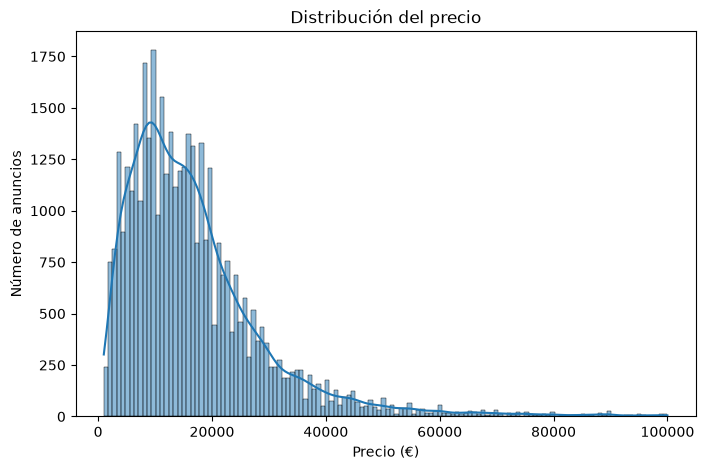

In [4]:
plt.figure(figsize=(8, 5))
sns.histplot(df['price'], kde=True)
plt.title('Distribución del precio')
plt.xlabel('Precio (€)')
plt.ylabel('Número de anuncios')
plt.show()

Asimetría del precio: cuanto más lejos de 0, más larga es la cola.

In [5]:
print('Asimetría del precio:', round(df['price'].skew(), 1))

Asimetría del precio: 2.1


### El precio en escala logarítmica

El precio tiene una cola muy larga a la derecha (asimetría ≈ 2,1): muchos coches baratos y pocos muy caros. El logaritmo "comprime" los valores grandes, de modo que una subida de 5.000 a 10.000 € ocupa lo mismo que de 50.000 a 100.000 €. Así vemos mejor la forma real de la distribución y comprobamos si al modelo le vendría bien predecir el log del precio.

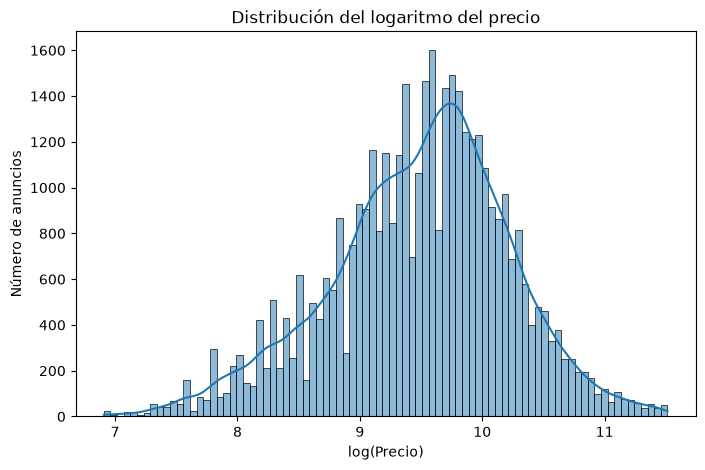

In [6]:
plt.figure(figsize=(8, 5))
sns.histplot(np.log(df['price']), kde=True)
plt.title('Distribución del logaritmo del precio')
plt.xlabel('log(Precio)')
plt.ylabel('Número de anuncios')
plt.savefig('../outputs/figures/03_distribucion_log_precio.png', bbox_inches='tight')
plt.show()

### Alta gama: coches de 60.000 € a 100.000 €

Llamamos **alta gama** a los coches con precio entre 60.000 € y 100.000 €. Contamos cuántos hay y qué parte del total son.

In [7]:
df_alta = df[(df['price'] >= 60000) & (df['price'] <= 100000)]
df_alta.shape

(578, 13)

In [8]:
print('Coches de alta gama:', len(df_alta))
print('Porcentaje sobre el total (%):', round(len(df_alta) / len(df) * 100, 1))

Coches de alta gama: 578
Porcentaje sobre el total (%): 1.4


Marcas con más coches de alta gama.

In [9]:
df_alta['make'].value_counts().head(10)

make
MERCEDES-BENZ    179
PORSCHE           96
AUDI              80
BMW               76
LAND-ROVER        57
MASERATI          19
JAGUAR            18
VOLVO             13
BENTLEY            6
VOLKSWAGEN         4
Name: count, dtype: int64

### Observaciones (Pregunta 1)

- En el dataset limpio quedan **40.614** anuncios, con precio entre **1.000 €** y **100.000 €**, mediana **14.100 €** y media **16.991 €**. La media sigue por encima de la mediana por los coches caros.
- El precio sigue teniendo cola a la derecha (asimetría ≈ **2,1**), aunque mucho menos larga que antes del corte.
- **Escala logarítmica:** la asimetría baja a ≈ **−0,4** y la distribución se parece mucho más a una campana.
- **Alta gama (60.000 € a 100.000 €):** hay **578** coches, el **1,4 %** del total. Las marcas con más coches en esta franja son Mercedes-Benz (179), Porsche (96), Audi (80) y BMW (76).

### Pregunta 2: ¿Cuánto se deprecia un coche por cada año de antigüedad?

**Por qué importa para el negocio:** la antigüedad es, junto con los kilómetros, lo primero que mira un tasador. Saber cuánto valor pierde de media un coche cada año nos da una regla sencilla para comprobar que el modelo tiene sentido, y es la base para estudiar las hipótesis H1 (alta gama) y H2 (marcas).

Para esta pregunta usamos una copia, df_p2, del dataset limpio. El df original no se modifica.

In [10]:
df_p2 = df.copy()
df_p2.shape

(40614, 13)

Calculamos la mediana del precio por año de fabricación, desde 2006 (el corte que hicimos en 02_limpieza) hasta 2020. Usamos la mediana y no la media porque el precio tiene cola a la derecha. Dejamos fuera 2021 porque el dataset se capturó el 15-01-2021 y hay muy pocos anuncios de ese año.

In [11]:
df_p2_años = df_p2[df_p2['year'] <= 2020]
mediana_año = df_p2_años.groupby('year')['price'].median()
mediana_año

year
2006     3999.0
2007     4700.0
2008     5900.0
2009     6500.0
2010     7490.0
2011     8900.0
2012     9800.0
2013    11000.0
2014    12400.0
2015    14425.0
2016    15490.0
2017    16900.0
2018    16950.0
2019    20650.0
2020    24990.0
Name: price, dtype: float64

Cuántos anuncios hay en cada año, para saber si cada mediana se apoya en suficientes coches.

In [12]:
df_p2_años['year'].value_counts().sort_index()

year
2006    1808
2007    2149
2008    1822
2009    1432
2010    1612
2011    1525
2012    1385
2013    1483
2014    1963
2015    3052
2016    5193
2017    4436
2018    3886
2019    4387
2020    4157
Name: count, dtype: int64

Gráfico de líneas de la mediana del precio por año.

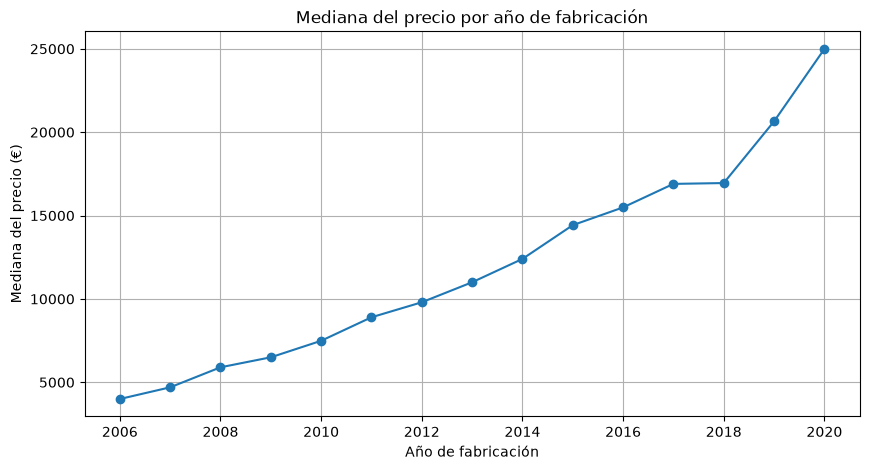

In [13]:
plt.figure(figsize=(10, 5))
plt.plot(mediana_año.index, mediana_año.values, marker='o')
plt.title('Mediana del precio por año de fabricación')
plt.xlabel('Año de fabricación')
plt.ylabel('Mediana del precio (€)')
plt.grid(True)
plt.savefig('../outputs/figures/04_mediana_precio_por_anio.png', bbox_inches='tight')
plt.show()

Calculamos cuánto se pierde al pasar de un año al anterior: si un coche de 2019 vale de mediana 20.500 € y uno de 2018 vale 16.950 €, un año más de antigüedad supone perder un 17 %. Lo hacemos para todos los años y sacamos la media y la mediana de esas pérdidas.

In [14]:
perdida_anual = (1 - mediana_año / mediana_año.shift(-1)) * 100
perdida_anual.round(1)

year
2006    14.9
2007    20.3
2008     9.2
2009    13.2
2010    15.8
2011     9.2
2012    10.9
2013    11.3
2014    14.0
2015     6.9
2016     8.3
2017     0.3
2018    17.9
2019    17.4
2020     NaN
Name: price, dtype: float64

In [15]:
print('Pérdida media por año de antigüedad (%):', round(perdida_anual.mean(), 1))
print('Pérdida mediana por año de antigüedad (%):', round(perdida_anual.median(), 1))

Pérdida media por año de antigüedad (%): 12.1
Pérdida mediana por año de antigüedad (%): 12.3


### Observaciones (Pregunta 2)

- Para esta pregunta quedan **40.614** anuncios. Todos los años de 2006 a 2020 tienen al menos 1.385 anuncios, así que cada mediana se apoya en bastantes coches.
- La mediana baja de forma muy regular con la antigüedad: **24.990 €** para un coche de 2020, **14.425 €** para uno de 2015, **7.490 €** para uno de 2010 y **3.999 €** para uno de 2006.
- De media, **cada año de antigüedad resta alrededor de un 11-12 % del precio** (media 12,1 %, mediana 12,3 %). Como es un porcentaje, el coche pierde más euros cuando es nuevo que cuando ya es viejo: la curva es exponencial, no una recta.
- Los primeros años son los que más pesan: de 2020 a 2019 se pierde un 17,4 % y de 2019 a 2018 un 17,9 %.
- Hay saltos raros: de 2018 a 2017 casi no baja (0,3 %). Pueden deberse a cambios en qué coches se anuncian cada año (más marcas premium o más kilómetros en unos años que en otros). Por eso la cifra es orientativa y la estudiaremos por marca.
- **Relación con las hipótesis:** esta cifra del 11-12 % anual es la referencia de "la media". Para **H1** compararemos la depreciación de las marcas de alta gama con este valor; para **H2**, la de Volkswagen. Todavía no concluimos nada: lo veremos por marca y lo confirmaremos con SHAP en 06_explicabilidad_negocio.
- **Idea para el modelado:** como la caída es exponencial, el logaritmo del precio baja casi en línea recta con el año. Es otro motivo para probar a predecir log(price), como se propuso en la Pregunta 1.
- **Corte por antigüedad:** en 02_limpieza nos quedamos con coches de **hasta 15 años** (fabricados en 2006 o después). Es una decisión de negocio: la empresa se centra en coches de 0 a 15 años, donde la caída del precio es clara y predecible.

### Pregunta 3: ¿Cuánto baja el precio por cada 10.000 km?

**Por qué importa para el negocio:** los kilómetros son, junto con el año, lo primero que mira un tasador. Saber cuánto valor resta cada 10.000 km nos da una regla sencilla para negociar con el cliente y para comprobar que el modelo tiene sentido.

Usamos una copia, df_p3, del dataset limpio, que ya tiene los cortes hechos en 02_limpieza: precio entre 1.000 € y 100.000 €, hasta 1.000.000 km y coches de 2006 en adelante. El df original no se modifica.

In [16]:
df_p3 = df.copy()
df_p3.shape

(40614, 13)

Agrupamos los kilómetros en tramos de 10.000 km. Con la división entera (//) un coche de 47.300 km cae en el tramo 40.000. Nos quedamos hasta 300.000 km, porque por encima hay muy pocos anuncios por tramo.

In [17]:
df_p3['tramo_kms'] = (df_p3['kms'] // 10000) * 10000
df_p3_tramos = df_p3[df_p3['tramo_kms'] < 300000]
mediana_kms = df_p3_tramos.groupby('tramo_kms')['price'].median()
mediana_kms

tramo_kms
0         23990.0
10000     20290.0
20000     18899.5
30000     16990.0
40000     16275.0
50000     16000.0
60000     15674.5
70000     14900.0
80000     13992.5
90000     13900.0
100000    12700.0
110000    12000.0
120000    10900.0
130000    10890.0
140000     9500.0
150000     8999.0
160000     8350.0
170000     7999.0
180000     7500.0
190000     6600.0
200000     6000.0
210000     6200.0
220000     6000.0
230000     5800.0
240000     5400.0
250000     5300.0
260000     5500.0
270000     4800.0
280000     4650.0
290000     4925.0
Name: price, dtype: float64

Cuántos anuncios hay en cada tramo, para saber si cada mediana se apoya en suficientes coches.

In [18]:
df_p3_tramos['tramo_kms'].value_counts().sort_index()

tramo_kms
0         5557
10000     2601
20000     2330
30000     1806
40000     1846
50000     1823
60000     1868
70000     1870
80000     2018
90000     2190
100000    1526
110000    1653
120000    1614
130000    1459
140000    1339
150000    1209
160000    1078
170000     938
180000     864
190000     822
200000     677
210000     509
220000     522
230000     431
240000     363
250000     328
260000     257
270000     215
280000     166
290000     140
Name: count, dtype: int64

Gráfico de líneas de la mediana del precio por tramo de kilómetros.

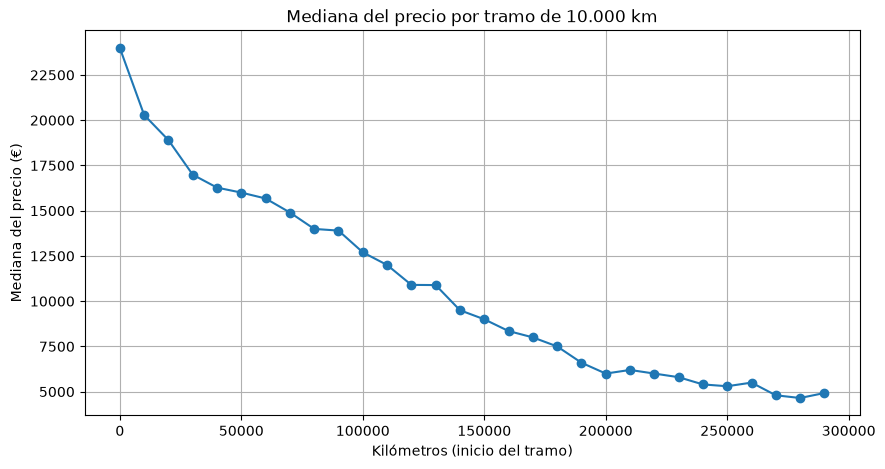

In [19]:
plt.figure(figsize=(10, 5))
plt.plot(mediana_kms.index, mediana_kms.values, marker='o')
plt.title('Mediana del precio por tramo de 10.000 km')
plt.xlabel('Kilómetros (inicio del tramo)')
plt.ylabel('Mediana del precio (€)')
plt.grid(True)
plt.savefig('../outputs/figures/05_mediana_precio_por_kms.png', bbox_inches='tight')
plt.show()

Calculamos cuánto baja la mediana, de media, por cada 10.000 km: la diferencia entre el primer y el último tramo, dividida entre el número de saltos de 10.000 km que hay entre ellos.

In [20]:
primer_tramo = mediana_kms.iloc[0]
ultimo_tramo = mediana_kms.iloc[-1]
saltos = len(mediana_kms) - 1
print('Mediana primer tramo (€):', primer_tramo)
print('Mediana último tramo (€):', ultimo_tramo)
print('Bajada media por cada 10.000 km (€):', round((primer_tramo - ultimo_tramo) / saltos))
print('Bajada media por cada 10.000 km (% del primer tramo):', round((primer_tramo - ultimo_tramo) / saltos / primer_tramo * 100, 1))

Mediana primer tramo (€): 23990.0
Mediana último tramo (€): 4925.0
Bajada media por cada 10.000 km (€): 657
Bajada media por cada 10.000 km (% del primer tramo): 2.7


Comprobamos la relación entre kilómetros y año: si los coches viejos tienen más kilómetros, parte de la bajada se debe a la edad.

In [21]:
print('Correlación entre kms y year:', round(df_p3['kms'].corr(df_p3['year']), 2))

Correlación entre kms y year: -0.77


### Observaciones (Pregunta 3)

- Para esta pregunta quedan **40.614** anuncios con los cortes (precio de 1.000 € a 100.000 €, hasta 1.000.000 km y de 2006 en adelante). Todos los tramos hasta 300.000 km tienen al menos 140 anuncios.
- La mediana baja de forma muy regular con los kilómetros: **23.990 €** con menos de 10.000 km, **12.700 €** entre 100.000 y 110.000 km, **6.000 €** entre 200.000 y 210.000 km y **4.925 €** entre 290.000 y 300.000 km.
- De media, **cada 10.000 km restan unos 657 €** de la mediana, alrededor de un **2,7 %** del precio del primer tramo.
- La bajada es más fuerte al principio: solo de 0 a 10.000 km se pierden unos 3.700 €. Muchos de esos coches son prácticamente nuevos (km 0 o seminuevos).
- **Ojo: kilómetros y año están muy relacionados** (correlación de −0,77). Los coches viejos tienen más kilómetros, así que **parte de esta bajada se debe a la edad** y no solo a los kilómetros. El modelo podrá separar el efecto de cada variable; en 06_explicabilidad_negocio lo veremos con SHAP.

### Pregunta 4: ¿Qué marcas conservan mejor su valor frente a otras?

**Por qué importa para el negocio:** si una marca pierde poco valor con los años, la empresa puede ofrecer más por ella sin arriesgar el margen; si pierde mucho, conviene ser más prudente. Además, es la primera comprobación de H1 (alta gama) y H2 (marcas).

Usamos una copia, df_p4, del dataset limpio, igual que en la Pregunta 3. El df original no se modifica.

In [22]:
df_p4 = df.copy()
df_p4.shape

(40614, 13)

Nos quedamos con las marcas que tienen al menos 1.000 anuncios, para que cada mediana se apoye en suficientes coches.

In [23]:
conteo_marcas = df_p4['make'].value_counts()
marcas = conteo_marcas[conteo_marcas >= 1000].index
df_p4_marcas = df_p4[df_p4['make'].isin(marcas)]
conteo_marcas[conteo_marcas >= 1000]

make
VOLKSWAGEN       3678
BMW              3572
MERCEDES-BENZ    3291
AUDI             3067
PEUGEOT          2736
FORD             2570
RENAULT          2395
OPEL             2366
CITROEN          2242
SEAT             1977
NISSAN           1400
TOYOTA           1366
FIAT             1241
KIA              1038
HYUNDAI          1012
Name: count, dtype: int64

Comparamos dos grupos de coches de cada marca: los **recientes** (de 2018 a 2020) y los de **5 a 7 años** (de 2013 a 2015). El valor retenido es la mediana de los de 2013-2015 dividida entre la mediana de los recientes: si sale 60 %, un coche de esa marca con unos 5 años más conserva el 60 % del precio.

In [24]:
recientes = df_p4_marcas[df_p4_marcas['year'] >= 2018]
antiguos = df_p4_marcas[(df_p4_marcas['year'] >= 2013) & (df_p4_marcas['year'] <= 2015)]

valor_marcas = pd.DataFrame()
valor_marcas['mediana_2018_2020'] = recientes.groupby('make')['price'].median()
valor_marcas['mediana_2013_2015'] = antiguos.groupby('make')['price'].median()
valor_marcas['anuncios_2018_2020'] = recientes['make'].value_counts()
valor_marcas['anuncios_2013_2015'] = antiguos['make'].value_counts()
valor_marcas['valor_retenido_%'] = (valor_marcas['mediana_2013_2015'] / valor_marcas['mediana_2018_2020'] * 100).round(1)
valor_marcas = valor_marcas.sort_values('valor_retenido_%', ascending=False)
valor_marcas

,mediana_2018_2020,mediana_2013_2015,anuncios_2018_2020,anuncios_2013_2015,valor_retenido_%
make,,,,,
FIAT,11400.0,7200.0,535,171,63.2
AUDI,29900.0,18500.0,595,588,61.9
VOLKSWAGEN,23004.0,13955.0,841,706,60.7
KIA,17690.0,10500.0,573,110,59.4
CITROEN,15590.0,9195.0,798,324,59.0
BMW,31575.0,18494.5,680,692,58.6
MERCEDES-BENZ,36500.0,20400.0,1029,602,55.9
HYUNDAI,18200.0,9999.0,493,139,54.9
TOYOTA,20100.0,10990.0,399,173,54.7


Gráfico de barras del valor retenido por marca.

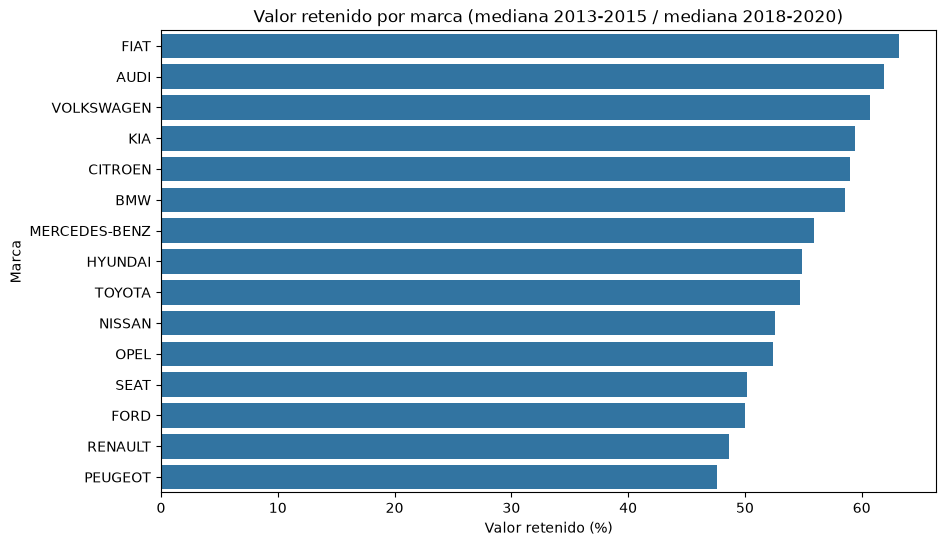

In [25]:
plt.figure(figsize=(10, 6))
sns.barplot(x=valor_marcas['valor_retenido_%'], y=valor_marcas.index)
plt.title('Valor retenido por marca (mediana 2013-2015 / mediana 2018-2020)')
plt.xlabel('Valor retenido (%)')
plt.ylabel('Marca')
plt.savefig('../outputs/figures/06_valor_retenido_por_marca.png', bbox_inches='tight')
plt.show()

Calculamos la media de esas marcas, para compararlas con una referencia.

In [26]:
print('Valor retenido medio de las marcas (%):', round(valor_marcas['valor_retenido_%'].mean(), 1))

Valor retenido medio de las marcas (%): 55.3


### Observaciones (Pregunta 4)

- Para esta pregunta quedan **40.614** anuncios con los cortes, y **15 marcas** con al menos 1.000 anuncios. Cada marca tiene al menos 399 anuncios recientes (2018-2020) y 110 de 2013-2015.
- Las marcas que **mejor mantienen su valor** son **Fiat (63,2 %)**, **Audi (61,9 %)**, **Volkswagen (60,7 %)**, **Kia (59,4 %)** y **Citroën (59 %)**.
- Las que **peor lo mantienen** son **Peugeot (47,6 %)**, **Renault (48,6 %)**, **Ford (50 %)** y **Seat (50,2 %)**.
- La media de las 15 marcas es **55,3 %**: con unos 5 años más, un coche conserva de mediana algo más de la mitad de su precio.
- **H1 (alta gama se deprecia más rápido):** en esta primera mirada **no se cumple**. Audi (61,9 %) y BMW (58,6 %) están por encima de la media y Mercedes-Benz (55,9 %) ligeramente por encima.
- **H2 (hay marcas que se deprecian menos que la media y otras más):** en esta primera mirada **sí se cumple**: Fiat, Audi, Volkswagen, Kia y Citroën están por encima de la media, y Peugeot, Renault, Ford y Seat por debajo.
- **Ojo:** es una comparación sencilla. Dentro de cada marca no comparamos los mismos modelos ni los mismos kilómetros en los dos grupos (por ejemplo, Fiat puede salir alta porque abundan modelos pequeños y baratos como el 500). Por eso es solo una primera mirada.

### Pregunta 5: ¿Cómo influyen el combustible y el tipo de cambio?

**Por qué importa para el negocio:** el combustible y el cambio (manual o automático) se ven en el anuncio y el cliente los conoce. Si un automático o un híbrido valen claramente más, la oferta tiene que reflejarlo. Además, es la primera comprobación de H3 (a igual año, eléctrico > diésel > gasolina).

Usamos una copia, df_p5, del dataset limpio. El df original no se modifica.

In [27]:
df_p5 = df.copy()
df_p5.shape

(40614, 13)

Cuántos anuncios hay de cada combustible y de cada tipo de cambio.

In [28]:
df_p5['fuel'].value_counts()

fuel
Diésel                25469
Gasolina              12719
Híbrido                1172
Eléctrico               549
Híbrido enchufable      500
Gas licuado (GLP)       114
Gas natural (CNG)        91
Name: count, dtype: int64

In [29]:
df_p5['shift'].value_counts()

shift
Manual        26970
Automático    13644
Name: count, dtype: int64

Mediana del precio y mediana del año por combustible. Miramos también el año porque, si un combustible tiene coches más nuevos, saldrá más caro solo por eso.

In [30]:
combustible = pd.DataFrame()
combustible['mediana_precio'] = df_p5.groupby('fuel')['price'].median()
combustible['mediana_año'] = df_p5.groupby('fuel')['year'].median()
combustible['anuncios'] = df_p5['fuel'].value_counts()
combustible.sort_values('mediana_precio', ascending=False)

,mediana_precio,mediana_año,anuncios
fuel,,,
Híbrido enchufable,35762.0,2020.0,500
Eléctrico,25583.0,2019.0,549
Híbrido,19995.0,2018.0,1172
Gas natural (CNG),16740.0,2019.0,91
Gasolina,13990.0,2017.0,12719
Diésel,13500.0,2015.0,25469
Gas licuado (GLP),9590.0,2018.0,114


Lo mismo para el tipo de cambio.

In [31]:
cambio = pd.DataFrame()
cambio['mediana_precio'] = df_p5.groupby('shift')['price'].median()
cambio['mediana_año'] = df_p5.groupby('shift')['year'].median()
cambio['anuncios'] = df_p5['shift'].value_counts()
cambio

,mediana_precio,mediana_año,anuncios
shift,,,
Automático,22990.0,2016.0,13644
Manual,11000.0,2016.0,26970


Para comparar coches de año parecido (lo que pide H3), repetimos el cálculo solo con los coches de 2018 a 2020.

In [32]:
df_p5_recientes = df_p5[df_p5['year'] >= 2018]
df_p5_recientes.shape

(12754, 13)

In [33]:
combustible_recientes = pd.DataFrame()
combustible_recientes['mediana_precio'] = df_p5_recientes.groupby('fuel')['price'].median()
combustible_recientes['anuncios'] = df_p5_recientes['fuel'].value_counts()
combustible_recientes = combustible_recientes.sort_values('mediana_precio', ascending=False)
combustible_recientes

,mediana_precio,anuncios
fuel,,
Híbrido enchufable,36900.0,380
Eléctrico,28500.0,392
Diésel,23890.0,5093
Híbrido,23370.0,629
Gasolina,17900.0,6108
Gas natural (CNG),17200.0,70
Gas licuado (GLP),11475.0,82


In [34]:
cambio_recientes = pd.DataFrame()
cambio_recientes['mediana_precio'] = df_p5_recientes.groupby('shift')['price'].median()
cambio_recientes['anuncios'] = df_p5_recientes['shift'].value_counts()
cambio_recientes

,mediana_precio,anuncios
shift,,
Automático,30800.0,4930
Manual,17400.0,7824


Gráfico de barras de la mediana del precio por combustible, con los coches de 2018 a 2020.

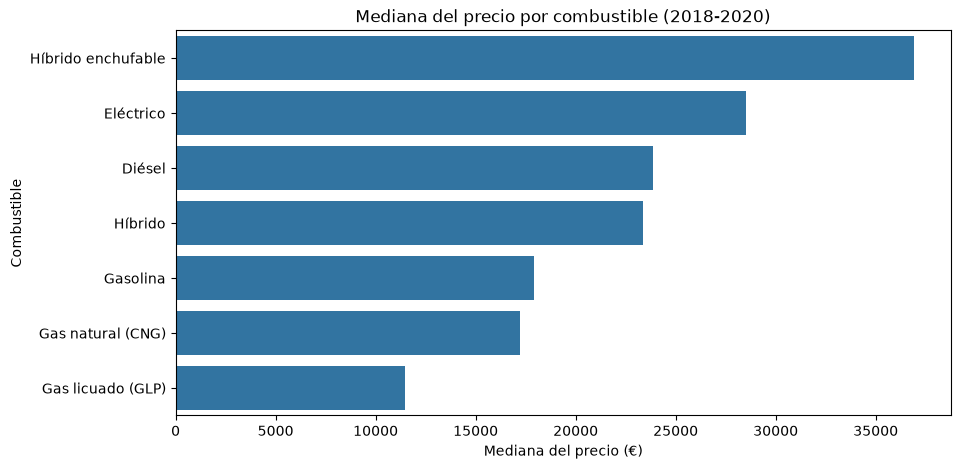

In [35]:
plt.figure(figsize=(10, 5))
sns.barplot(x=combustible_recientes['mediana_precio'], y=combustible_recientes.index)
plt.title('Mediana del precio por combustible (2018-2020)')
plt.xlabel('Mediana del precio (€)')
plt.ylabel('Combustible')
plt.savefig('../outputs/figures/07_mediana_precio_por_combustible.png', bbox_inches='tight')
plt.show()

Gráfico de barras de la mediana del precio por tipo de cambio, con los coches de 2018 a 2020.

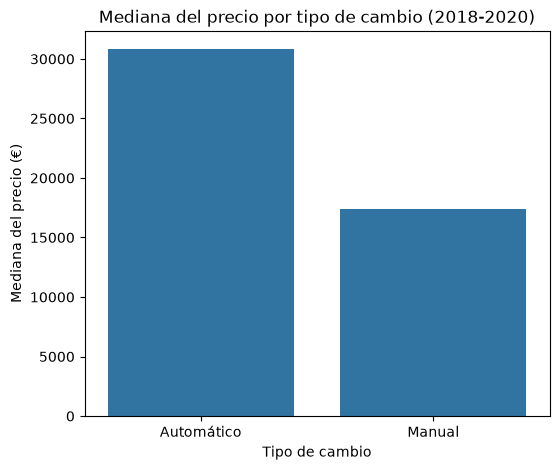

In [36]:
plt.figure(figsize=(6, 5))
sns.barplot(x=cambio_recientes.index, y=cambio_recientes['mediana_precio'])
plt.title('Mediana del precio por tipo de cambio (2018-2020)')
plt.xlabel('Tipo de cambio')
plt.ylabel('Mediana del precio (€)')
plt.savefig('../outputs/figures/08_mediana_precio_por_cambio.png', bbox_inches='tight')
plt.show()

### Observaciones (Pregunta 5)

- Para esta pregunta tenemos los **40.614** anuncios del dataset limpio. Dominan el **diésel (25.469)** y la **gasolina (12.719)**; híbridos (1.172), eléctricos (549), híbridos enchufables (500) y gas (114 GLP y 91 GNC) son pocos.
- **Combustible, con todos los años:** diésel (13.500 €) y gasolina (13.990 €) casi empatan. Los híbridos enchufables (35.762 €), eléctricos (25.583 €) e híbridos (19.995 €) salen mucho más caros, pero también son más nuevos: mediana de año 2020, 2019 y 2018, frente a 2015 del diésel.
- **Combustible, solo 2018-2020:** híbrido enchufable **36.900 €**, eléctrico **28.500 €**, diésel **23.890 €**, híbrido 23.370 €, gasolina **17.900 €**, GNC 17.200 € y GLP 11.475 €.
- **Cambio:** un automático vale de mediana **22.990 €** y un manual **11.000 €**, con la misma mediana de año (2016). En 2018-2020 la diferencia se mantiene: **30.800 €** frente a **17.400 €** (unos 13.400 € más).
- **H3 (a igual año, eléctrico > diésel > gasolina):** en esta primera mirada **queda apoyada** con los coches de 2018 a 2020: eléctrico 28.500 €, diésel 23.890 € y gasolina 17.900 €. Con todos los años no se ve, porque diésel y gasolina casi empatan.
- **Ojo:** la diferencia puede no deberse solo al combustible o al cambio, porque otras variables (marca, modelo, potencia y kilómetros) también cambian de un grupo a otro.